Préparation du jeu de données version 2

Ce notebook construit un jeu de données commun pour le premier modèle de la version 2 :
**la pièce est-elle en bon état ou endommagée ?**

Il ne modifie pas `data/sources/`. Il crée une copie préparée dans `data/v2/` :

```
data/v2/
    train/  bon_etat/  endommage/
    val/    bon_etat/  endommage/
    test/   bon_etat/  endommage/
```

Étapes :
1. choisir les dossiers sources et leur classe;
2. retirer les doublons exacts (empreinte MD5);
3. découper en entraînement (70 %), validation (15 %) et test (15 %), séparément pour chaque source et chaque classe;
4. copier les images en les réduisant à 512 pixels au maximum;
5. enregistrer un manifeste (`resultats/v2_manifeste.csv`) qui indique d'où vient chaque image.

Cliquez sur **Run All**. La préparation prend quelques minutes, surtout à cause des photos de pneus en haute résolution.

In [1]:
import hashlib
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageOps

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SOURCES = RACINE / "data" / "sources"
SORTIE = RACINE / "data" / "v2"
MANIFESTE = RACINE / "resultats" / "v2_manifeste.csv"

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
TAILLE_MAX = 512
PARTS = {"train": 0.70, "val": 0.15, "test": 0.15}
GRAINE = 42

plt.rcParams["figure.dpi"] = 110

## 1. Dossiers sources retenus

Seules les photos **originales** de Casting (`casting_512x512`) sont utilisées.
Le dossier `casting_data` contient des versions augmentées de ces mêmes pièces : les utiliser
risquerait de placer deux versions d'une même pièce dans l'entraînement et dans le test.

Pour ajouter un jeu plus tard, il suffira d'ajouter une ligne à cette liste.

In [2]:
PNEUS = "pneus/Digital images of defective and good condition tyres"
SELECTION = [
    # (nom de la source, dossier dans data/sources, classe)
    ("casting", "casting/casting_512x512/casting_512x512/ok_front", "bon_etat"),
    ("casting", "casting/casting_512x512/casting_512x512/def_front", "endommage"),
    ("pneus", f"{PNEUS}/good", "bon_etat"),
    ("pneus", f"{PNEUS}/defective", "endommage"),
]

lignes = []
for source, dossier, classe in SELECTION:
    chemin = SOURCES / dossier
    if not chemin.is_dir():
        raise SystemExit(f"Dossier introuvable : {chemin}")
    for fichier in sorted(chemin.iterdir()):
        if fichier.suffix.lower() in EXTENSIONS:
            lignes.append({"source": source, "classe": classe, "origine": str(fichier.relative_to(SOURCES).as_posix())})

images = pd.DataFrame(lignes)
images.groupby(["source", "classe"]).size().unstack().rename_axis(None, axis=1)

,bon_etat,endommage
source,,
casting,519,781
pneus,828,1028


## 2. Retrait des doublons exacts

In [3]:
def empreinte(chemin):
    return hashlib.md5((SOURCES / chemin).read_bytes()).hexdigest()

images["md5"] = [empreinte(c) for c in images["origine"]]
doublons = images[images.duplicated("md5", keep="first")]
print(f"Doublons exacts trouvés : {len(doublons)}")
if len(doublons):
    display(doublons[["source", "classe", "origine"]])

# Une même image dans deux classes différentes serait une erreur d'étiquette : on la retire complètement
conflits = images.groupby("md5")["classe"].nunique()
conflits = set(conflits[conflits > 1].index)
print(f"Images présentes dans les deux classes (retirées) : {len(conflits)}")

images = images[~images["md5"].isin(conflits)].drop_duplicates("md5").reset_index(drop=True)
print(f"Images conservées : {len(images)}")

Doublons exacts trouvés : 28


,source,classe,origine
2413,pneus,endommage,pneus/Digital images of defective and good con...
2950,pneus,endommage,pneus/Digital images of defective and good con...
2952,pneus,endommage,pneus/Digital images of defective and good con...
2954,pneus,endommage,pneus/Digital images of defective and good con...
2956,pneus,endommage,pneus/Digital images of defective and good con...
2959,pneus,endommage,pneus/Digital images of defective and good con...
2961,pneus,endommage,pneus/Digital images of defective and good con...
2963,pneus,endommage,pneus/Digital images of defective and good con...
2965,pneus,endommage,pneus/Digital images of defective and good con...
2967,pneus,endommage,pneus/Digital images of defective and good con...


Images présentes dans les deux classes (retirées) : 0
Images conservées : 3128


## 3. Découpage entraînement / validation / test

Le découpage est fait séparément pour chaque source et chaque classe, afin que chaque partie garde les mêmes proportions.

In [4]:
rng = random.Random(GRAINE)
images["partie"] = ""
for (source, classe), groupe in images.groupby(["source", "classe"]):
    indices = list(groupe.index)
    rng.shuffle(indices)
    n = len(indices)
    n_train = round(n * PARTS["train"])
    n_val = round(n * PARTS["val"])
    images.loc[indices[:n_train], "partie"] = "train"
    images.loc[indices[n_train:n_train + n_val], "partie"] = "val"
    images.loc[indices[n_train + n_val:], "partie"] = "test"

repartition = images.pivot_table(index=["source", "classe"], columns="partie", values="md5",
                                 aggfunc="count")[["train", "val", "test"]]
repartition.loc[("Total", ""), :] = repartition.sum()
repartition.astype(int)

partie             train  val  test
source  classe                     
casting bon_etat     363   78    78
        endommage    547  117   117
pneus   bon_etat     580  124   124
        endommage    700  150   150
Total               2190  469   469

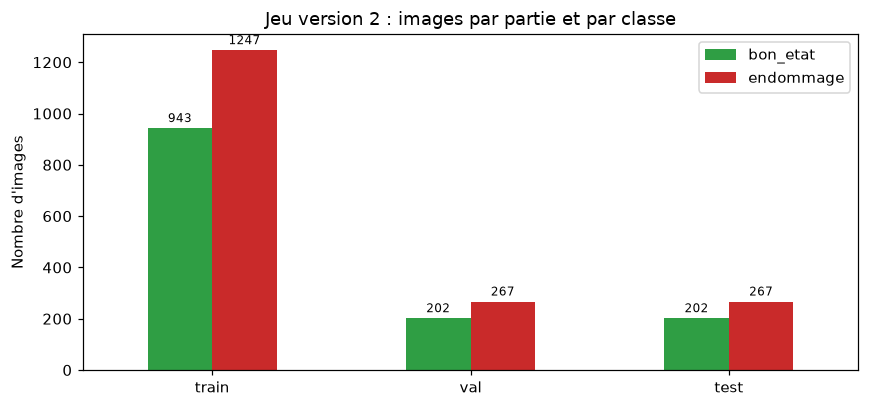

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
tableau = images.groupby(["partie", "classe"]).size().unstack().loc[["train", "val", "test"]]
tableau.plot.bar(ax=ax, color=["#2f9e44", "#c92a2a"], rot=0)
for conteneur in ax.containers:
    ax.bar_label(conteneur, fontsize=8, padding=2)
ax.set_xlabel("")
ax.set_ylabel("Nombre d'images")
ax.set_title("Jeu version 2 : images par partie et par classe")
ax.legend(title="")
plt.tight_layout()
plt.show()

## 4. Copie des images préparées

Chaque image est orientée correctement, convertie en couleur (RGB) et réduite à 512 pixels au maximum.

In [6]:
if SORTIE.exists():
    shutil.rmtree(SORTIE)  # on repart de zéro à chaque exécution

images["fichier"] = ""
compteur = {}
for i, ligne in images.iterrows():
    cle = (ligne["source"], ligne["classe"])
    compteur[cle] = compteur.get(cle, 0) + 1
    nom = f"{ligne['source']}_{ligne['classe']}_{compteur[cle]:04d}.jpg"
    destination = SORTIE / ligne["partie"] / ligne["classe"] / nom
    destination.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(SOURCES / ligne["origine"]) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im.thumbnail((TAILLE_MAX, TAILLE_MAX), Image.Resampling.LANCZOS)
        im.save(destination, quality=92)
    images.at[i, "fichier"] = str(destination.relative_to(RACINE).as_posix())
    if (i + 1) % 250 == 0:
        print(f"  {i + 1}/{len(images)} images copiées")

print(f"Terminé : {len(images)} images dans {SORTIE}")

  250/3128 images copiées
  500/3128 images copiées
  750/3128 images copiées
  1000/3128 images copiées
  1250/3128 images copiées
  1500/3128 images copiées
  1750/3128 images copiées
  2000/3128 images copiées
  2250/3128 images copiées
  2500/3128 images copiées
  2750/3128 images copiées
  3000/3128 images copiées
Terminé : 3128 images dans c:\Users\Jonathan\diagnostic-defauts\data\v2


## 5. Vérifications et manifeste

In [7]:
# Aucune image ne doit apparaître dans deux parties différentes
parties_par_image = images.groupby("md5")["partie"].nunique()
print("Images présentes dans plusieurs parties :", int((parties_par_image > 1).sum()))

# Le nombre de fichiers sur le disque doit correspondre au tableau
for partie in ["train", "val", "test"]:
    for classe in ["bon_etat", "endommage"]:
        n_disque = len(list((SORTIE / partie / classe).glob("*.jpg")))
        n_attendu = len(images[(images["partie"] == partie) & (images["classe"] == classe)])
        statut = "OK" if n_disque == n_attendu else "ÉCART"
        print(f"  {partie:<6} {classe:<10} {n_disque:>5} fichiers  {statut}")

MANIFESTE.parent.mkdir(exist_ok=True)
images[["fichier", "partie", "classe", "source", "origine", "md5"]].to_csv(MANIFESTE, index=False, encoding="utf-8")
print(f"\nManifeste enregistré : {MANIFESTE}")

Images présentes dans plusieurs parties : 0
  train  bon_etat     943 fichiers  OK
  train  endommage   1247 fichiers  OK
  val    bon_etat     202 fichiers  OK
  val    endommage    267 fichiers  OK
  test   bon_etat     202 fichiers  OK
  test   endommage    267 fichiers  OK

Manifeste enregistré : c:\Users\Jonathan\diagnostic-defauts\resultats\v2_manifeste.csv


## 6. Aperçu du jeu préparé

Quatre images d'entraînement par source et par classe.

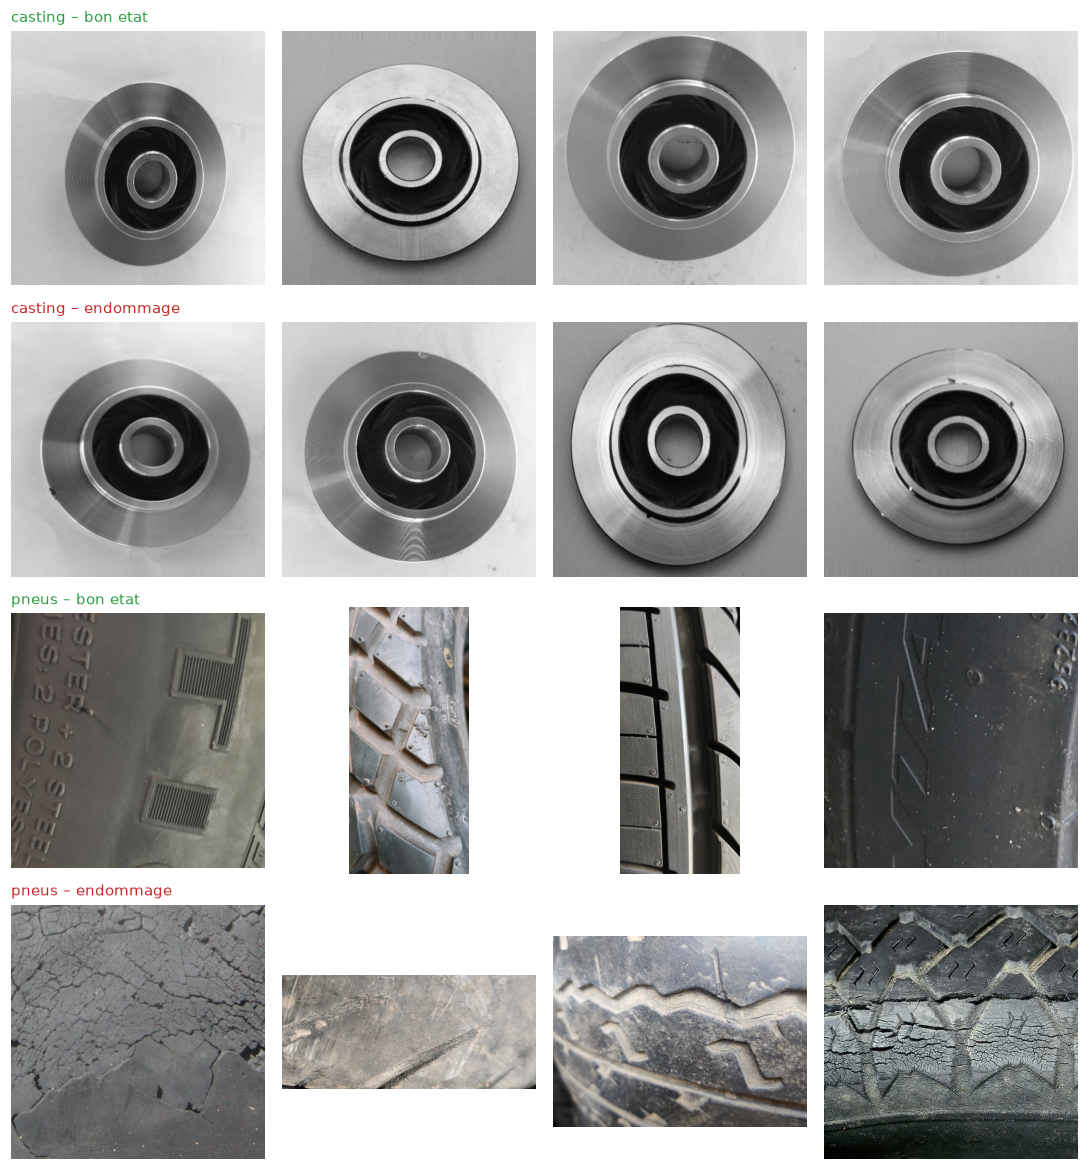

In [8]:
random.seed(1)
groupes = list(images[images["partie"] == "train"].groupby(["source", "classe"]))
fig, axes = plt.subplots(len(groupes), 4, figsize=(10, 2.7 * len(groupes)), squeeze=False)
for i, ((source, classe), groupe) in enumerate(groupes):
    for j, fichier in enumerate(random.sample(list(groupe["fichier"]), 4)):
        axes[i, j].imshow(Image.open(RACINE / fichier))
        axes[i, j].axis("off")
    axes[i, 0].set_title(f"{source} – {classe.replace('_', ' ')}", loc="left", fontsize=10,
                         color="#2f9e44" if classe == "bon_etat" else "#c92a2a")
plt.tight_layout()
plt.show()

## Prochaine étape

Envoyez à Claude une capture des sections 2, 3 et 5. Le jeu étant prêt, l'étape suivante
consistera à entraîner le modèle « bon état / endommagé ».